# 01 - Data preparation

**Project:** Can customer review sentiment help forecast weekly demand per product category? (Olist Brazilian E-Commerce dataset)

## What this notebook does
We take the raw Olist CSV files and turn them into **one clean table** that the next notebooks will use.

| Step | What we do | Why |
|---|---|---|
| 1 | Load the 5 CSV files we need | The other 4 files (customers, sellers, geolocation, payments) are not needed for this project |
| 2 | Inspect each table | Know what we are working with (size, missing values) |
| 3 | Keep **delivered** orders only | Cancelled or unfinished orders are not real demand, and have no delivery date |
| 4 | Compute delivery delay | Late delivery strongly affects review scores, so we control for it later |
| 5 | Reduce reviews to **one row per order** | Some orders have several reviews; merging them naively would create duplicates |
| 6 | Translate product categories to English | Olist gives Portuguese names; a translation file is provided |
| 7 | Build the order-category table | One row per (order, category) with dates, delay and review information |
| 8 | Quality checks and a first look at the time span | Catch problems early |
| 9 | Save to `data/processed/` | The next notebooks load this file directly |

## Key definitions (we will reuse them in the report)
- **Demand** = number of *distinct delivered orders* of a category in a given week (counted at purchase date).
- **Delivery delay** = actual delivery date - estimated delivery date, in days (positive = late).
- **Sentiment (main signal)** = the review score (1 to 5). Text analysis of the Portuguese comments is optional and only if time allows.

## Important note about time (avoiding data leakage)
A review only exists *after* the customer received the order. So for forecasting we must only use a review score from the date it was **answered** (`review_answer_timestamp`), never earlier. We keep both review dates here and check how they differ.

> **AI use log:** write in your `AI_log.md` that this notebook was produced with AI assistance for the code (date, what you asked, what was generated). The handbook requires it.

## 1. Setup and loading the data

We use `pathlib` to build file paths. `../data/raw` means: go up one folder (out of `notebooks/`), then into `data/raw`.
Dates are converted to real date types while loading (`parse_dates`), so we can compute with them (differences, weeks, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../outputs/figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
orders = pd.read_csv(
    RAW / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
)
items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
reviews = pd.read_csv(
    RAW / "olist_order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)
translation = pd.read_csv(RAW / "product_category_name_translation.csv")

## 2. First inspection of each table

For every table we print its size and the columns that contain missing values.
**Write down these numbers**: they go into the Methodology chapter (data description).

In [3]:
def inspect(df, name):
    print(f"=== {name} ===  rows: {len(df):,}  columns: {df.shape[1]}")
    missing = df.isna().sum()
    missing = missing[missing > 0]
    if len(missing) == 0:
        print("No missing values")
    else:
        print("Missing values per column:")
        print(missing.to_string())
    print()

for name, df in {
    "orders": orders,
    "order_items": items,
    "products": products,
    "reviews": reviews,
    "category translation": translation,
}.items():
    inspect(df, name)

orders.head(3)

=== orders ===  rows: 99,441  columns: 8
Missing values per column:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

=== order_items ===  rows: 112,650  columns: 7
No missing values

=== products ===  rows: 32,951  columns: 9
Missing values per column:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

=== reviews ===  rows: 99,224  columns: 7
Missing values per column:
review_comment_title      87656
review_comment_message    58247

=== category translation ===  rows: 71  columns: 2
No missing values



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


## 3. Keep delivered orders only

Orders can be `delivered`, `shipped`, `canceled`, `unavailable`, etc. We only want orders that really happened and reached the customer.
We also drop the few "delivered" orders that have no delivery date, because we cannot compute their delay.

In [4]:
n_before = len(orders)
print(orders["order_status"].value_counts().to_string())

orders = orders[orders["order_status"] == "delivered"].copy()
n_delivered = len(orders)

no_delivery_date = orders["order_delivered_customer_date"].isna().sum()
orders = orders.dropna(subset=["order_delivered_customer_date"]).copy()

print()
print(f"Orders before filter          : {n_before:,}")
print(f"Delivered orders kept         : {n_delivered:,} ({n_delivered / n_before:.1%})")
print(f"Delivered but no delivery date: {no_delivery_date:,} (dropped)")
print(f"Orders used from now on       : {len(orders):,}")

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Orders before filter          : 99,441
Delivered orders kept         : 96,478 (97.0%)
Delivered but no delivery date: 8 (dropped)
Orders used from now on       : 96,470


## 4. Delivery delay

Late deliveries are known to be the main driver of bad reviews on this dataset. If we ignore this, our "sentiment" signal could simply measure logistics problems.
So we compute the delay now and use it later as a **control variable**.

- `delivery_delay_days` > 0 means the order arrived *after* the promised date.
- `delivery_time_days` is the total time from purchase to delivery.

In [5]:
SECONDS_PER_DAY = 86400

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.total_seconds() / SECONDS_PER_DAY

orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / SECONDS_PER_DAY

orders["is_late"] = orders["delivery_delay_days"] > 0

print(orders[["delivery_delay_days", "delivery_time_days"]].describe().round(1).to_string())
print(f"\nShare of late deliveries: {orders['is_late'].mean():.1%}")

       delivery_delay_days  delivery_time_days
count              96470.0             96470.0
mean                 -11.2                12.6
std                   10.2                 9.5
min                 -146.0                 0.5
25%                  -16.2                 6.8
50%                  -11.9                10.2
75%                   -6.4                15.7
max                  189.0               209.6

Share of late deliveries: 8.1%


## 5. Reviews: one row per order

Two facts about Olist reviews:
1. An order can have **several reviews**. If we merged reviews directly onto orders, those orders would appear twice and be counted twice as demand.
2. Many reviews have **no written comment**, only a score from 1 to 5.

We first check the two review dates. `review_creation_date` and `review_answer_timestamp` do not mean the same thing, and the date that matters for forecasting is the one at which the score became **available to the business**: the answer date.

In [6]:
gap_days = (
    reviews["review_answer_timestamp"] - reviews["review_creation_date"]
).dt.total_seconds() / SECONDS_PER_DAY

print("Answer timestamp minus creation date (days):")
print(gap_days.describe().round(2).to_string())
print(f"\nReviews answered BEFORE their creation date: {(gap_days < 0).sum():,}")
reviews[["review_score", "review_creation_date", "review_answer_timestamp"]].head()

Answer timestamp minus creation date (days):
count    99224.00
mean         3.15
std          9.89
min          0.09
25%          1.00
50%          1.67
75%          3.10
max        518.70

Reviews answered BEFORE their creation date: 0


,review_score,review_creation_date,review_answer_timestamp
0,4,2018-01-18,2018-01-18 21:46:59
1,5,2018-03-10,2018-03-11 03:05:13
2,5,2018-02-17,2018-02-18 14:36:24
3,5,2017-04-21,2017-04-21 22:02:06
4,5,2018-03-01,2018-03-02 10:26:53


**How to read this:** if the gap is almost never negative, the answer timestamp is always the later (safer) date.
To avoid any leakage we will use **`review_answer_timestamp`** as the date at which a review becomes known.

In [7]:
reviews["has_comment"] = reviews["review_comment_message"].notna()

reviews_per_order = reviews.groupby("order_id")["review_id"].count()
print(f"Orders with at least one review: {len(reviews_per_order):,}")
print(f"Orders with more than one review: {(reviews_per_order > 1).sum():,}")

reviews_order = (
    reviews.groupby("order_id")
    .agg(
        review_score=("review_score", "mean"),           # average if several reviews
        n_reviews=("review_id", "count"),
        review_creation_date=("review_creation_date", "max"),
        review_answer_timestamp=("review_answer_timestamp", "max"),  # last answer = score complete
        has_comment=("has_comment", "max"),
    )
    .reset_index()
)

print(f"\nOne row per order now: {len(reviews_order):,} rows "
      f"(order_id unique: {reviews_order['order_id'].is_unique})")
print(f"Share of reviewed orders with a written comment: {reviews_order['has_comment'].mean():.1%}")
reviews_order.head(3)

Orders with at least one review: 98,673
Orders with more than one review: 547

One row per order now: 98,673 rows (order_id unique: True)
Share of reviewed orders with a written comment: 41.4%


,order_id,review_score,n_reviews,review_creation_date,review_answer_timestamp,has_comment
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1,2017-09-21,2017-09-22 10:57:03,True
1,00018f77f2f0320c557190d7a144bdd3,4.0,1,2017-05-13,2017-05-15 11:34:13,False
2,000229ec398224ef6ca0657da4fc703e,5.0,1,2018-01-23,2018-01-23 16:06:31,True


## 6. Product categories in English

Category names are in Portuguese. Olist provides a translation table. Two things can go wrong:
- a few categories are **missing from the translation table**: we keep their Portuguese name instead;
- some products have **no category at all**: we label them `unknown`.

In [8]:
products = products.merge(translation, on="product_category_name", how="left")

untranslated = (
    products.loc[
        products["product_category_name_english"].isna()
        & products["product_category_name"].notna(),
        "product_category_name",
    ]
    .unique()
)
print("Categories without an English translation (kept in Portuguese):", list(untranslated))

products["category"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"])
    .fillna("unknown")
)

print(f"\nNumber of distinct categories: {products['category'].nunique()}")
print(f"Products with unknown category: {(products['category'] == 'unknown').sum():,}")

Categories without an English translation (kept in Portuguese): ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Number of distinct categories: 74
Products with unknown category: 610


## 7. The order-category table

We link orders -> items -> products to know which categories each order contains.
We keep **one row per (order, category)**: if a customer buys two items of the same category in one order, that is still one order for that category.

Then we attach the order dates, the delivery delay and the review information.

**Limitation to mention in the report:** a review is about the *whole order*, not one category. If an order contains several categories, the same review is attached to each of them. We measure how often this happens just below.

In [9]:
items_cat = items.merge(products[["product_id", "category"]], on="product_id", how="left")
items_cat["category"] = items_cat["category"].fillna("unknown")

order_category = (
    items_cat.groupby(["order_id", "category"], as_index=False)
    .agg(n_items=("order_item_id", "count"), items_value=("price", "sum"))
)

order_columns = [
    "order_id",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_delay_days",
    "delivery_time_days",
    "is_late",
]

master = (
    order_category
    .merge(orders[order_columns], on="order_id", how="inner")   # inner = delivered orders only
    .merge(reviews_order, on="order_id", how="left")            # left = keep orders without review
)

print(f"Rows (order x category): {len(master):,}")
print(f"Distinct delivered orders: {master['order_id'].nunique():,}")
master.head(3)

Rows (order x category): 97,268
Distinct delivered orders: 96,470


,order_id,category,n_items,items_value,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_time_days,is_late,review_score,n_reviews,review_creation_date,review_answer_timestamp,has_comment
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,1,58.9,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,-8.011250,7.614421,False,5.0,1.0,2017-09-21,2017-09-22 10:57:03,True
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,1,239.9,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,-2.330278,16.216181,False,4.0,1.0,2017-05-13,2017-05-15 11:34:13,False
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,1,199.0,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,-13.444954,7.948437,False,5.0,1.0,2018-01-23,2018-01-23 16:06:31,True


## 8. Quality checks

We verify that nothing was duplicated or lost in the merges. If one of these checks fails, **stop and fix it before going further**.

In [10]:
assert not master.duplicated(["order_id", "category"]).any(), "duplicate order-category rows"
assert master["order_id"].nunique() <= len(orders), "more orders than delivered orders?"

cats_per_order = master.groupby("order_id")["category"].nunique()
print(f"Orders containing more than one category: {(cats_per_order > 1).mean():.1%}")

print(f"Delivered orders without a review: {master.drop_duplicates('order_id')['review_score'].isna().mean():.1%}")
print()
print("Missing values in the final table:")
print(master.isna().sum().to_string())

Orders containing more than one category: 0.8%
Delivered orders without a review: 0.7%

Missing values in the final table:
order_id                           0
category                           0
n_items                            0
items_value                        0
order_purchase_timestamp           0
order_delivered_customer_date      0
order_estimated_delivery_date      0
delivery_delay_days                0
delivery_time_days                 0
is_late                            0
review_score                     652
n_reviews                        652
review_creation_date             652
review_answer_timestamp          652
has_comment                      652


Purchase dates: 2016-09-15  ->  2018-08-29


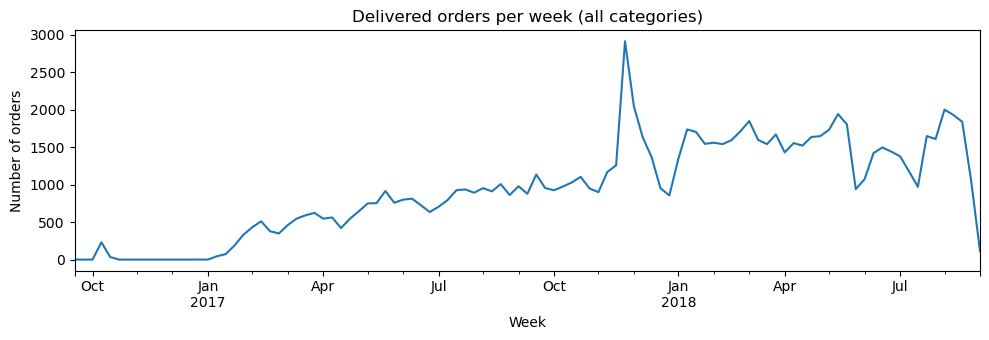

In [11]:
first_order = master["order_purchase_timestamp"].min()
last_order = master["order_purchase_timestamp"].max()
print(f"Purchase dates: {first_order.date()}  ->  {last_order.date()}")

weekly_orders = (
    master.drop_duplicates("order_id")
    .set_index("order_purchase_timestamp")
    .resample("W")["order_id"]
    .count()
)

fig, ax = plt.subplots(figsize=(10, 3.5))
weekly_orders.plot(ax=ax)
ax.set_title("Delivered orders per week (all categories)")
ax.set_xlabel("Week")
ax.set_ylabel("Number of orders")
plt.tight_layout()
fig.savefig(FIGURES / "01_weekly_orders_overview.png", dpi=150)
plt.show()

**What to look for in the graph:** the very first and very last weeks usually have very few orders (the dataset is a sample that starts and ends progressively).
We will decide which period to keep in notebook 02, after looking at the data in more detail.

## 9. Save the clean table

Notebook 02 will start from this file. We save it as CSV (simple and readable). Dates will be parsed again when reloading.

In [12]:
output_file = PROCESSED / "order_category.csv"
master.to_csv(output_file, index=False)
print(f"Saved {len(master):,} rows to {output_file}")

Saved 97,268 rows to ..\data\processed\order_category.csv


## Summary: numbers to note for the Methodology chapter
- Number of orders in the raw file, number delivered, number kept (section 3)
- Share of late deliveries (section 4)
- Number of orders with several reviews, and share with a written comment (section 5)
- Categories without translation, share of unknown category (section 6)
- Share of orders with more than one category (section 8)
- First and last purchase dates (section 8)

**Next notebook:** `02_eda.ipynb` - exploratory analysis, choice of the study period and of the categories.

**Suggested commit message:** `Add notebook 01: load, clean and merge Olist data`